## 🧠 Unsupervised Learning Practical

**Customer Segmentation using Kaggle Dataset**

*  Dataset: Mall_Customers.csv
*  Learning Type: Unsupervised Learning
*  Algorithms: K-Means (main), with understanding of clustering
*  Goal: Discover hidden customer groups

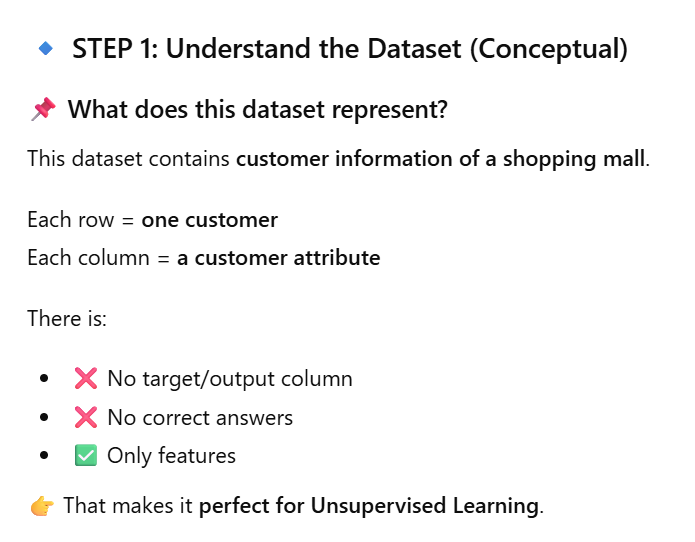

In [4]:
# 🔹 STEP 2: Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [5]:
df = pd.read_csv("/content/Mall_Customers.csv")


In [6]:
df.head()


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [7]:
df.shape


(200, 5)

In [8]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Genre                   200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [9]:
df.describe()


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


## 🔹: Feature Selection (Very Important)

For clustering, we choose behavior-based numerical features.

In [10]:
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]


🧠 Why these features?

*   Income shows earning capacity
*   Spending score shows shopping behavior
*   Together → excellent for segmentation

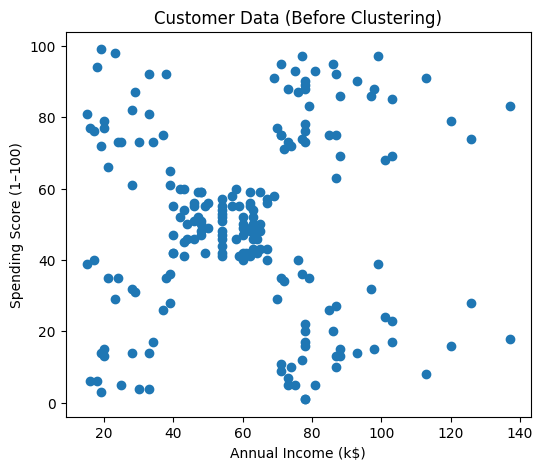

In [11]:
plt.figure(figsize=(6, 5))
plt.scatter(
    X['Annual Income (k$)'],
    X['Spending Score (1-100)']
)
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1–100)")
plt.title("Customer Data (Before Clustering)")
plt.show()


*  Can you see groups?

*  Who are high-income high-spending customers?

*  Who earns a lot but spends less?

# 🟢 K-MEANS CLUSTERING

In [12]:
from sklearn.cluster import KMeans


Choosing Number of Clusters (Elbow Method)
📌 Why?

K-Means requires us to choose K (number of clusters).

In [13]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)


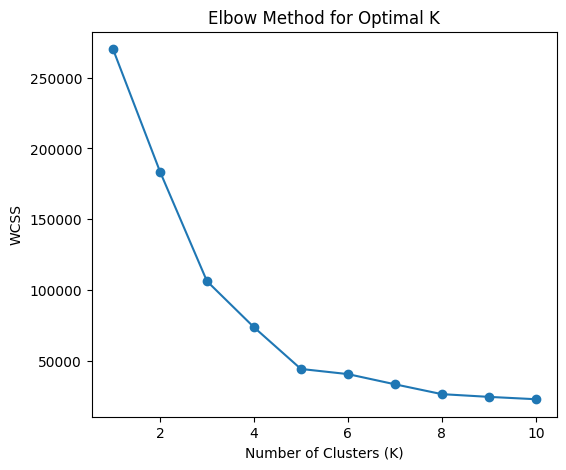

In [14]:
plt.figure(figsize=(6, 5))
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method for Optimal K")
plt.show()


WCSS = within-cluster sum of squares

Elbow point = best K

Usually K = 5 for this dataset

# Apply K-Means with Optimal K

In [15]:
kmeans = KMeans(n_clusters=5, random_state=42)
clusters = kmeans.fit_predict(X)

# Add Cluster Labels to Dataset

In [16]:
df['Cluster'] = clusters
df.head()


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,Male,19,15,39,4
1,2,Male,21,15,81,2
2,3,Female,20,16,6,4
3,4,Female,23,16,77,2
4,5,Female,31,17,40,4


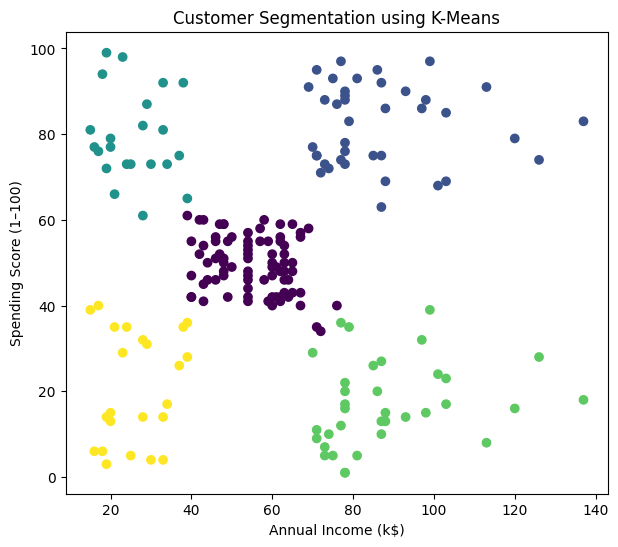

In [18]:
plt.figure(figsize=(7, 6))
plt.scatter(
    X['Annual Income (k$)'],
    X['Spending Score (1-100)'],
    c=clusters,
    cmap='viridis'
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1–100)")
plt.title("Customer Segmentation using K-Means")
plt.show()


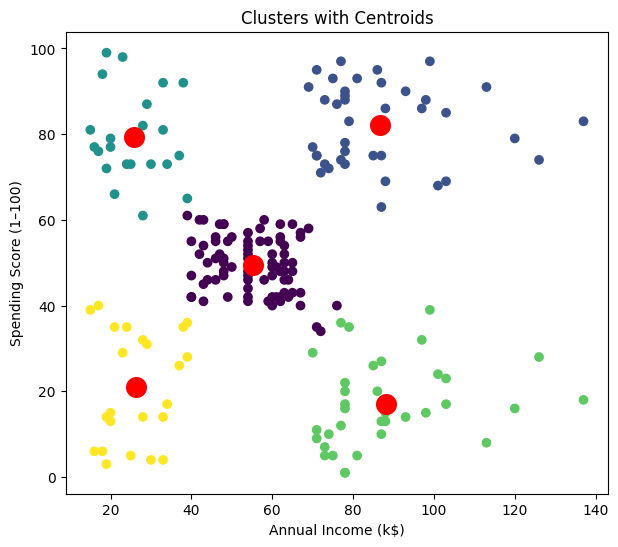

In [21]:
centers = kmeans.cluster_centers_

plt.figure(figsize=(7, 6))
plt.scatter(
    X['Annual Income (k$)'],
    X['Spending Score (1-100)'],
    c=clusters,
    cmap='viridis'
)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c='red',
    s=200,
    marker='o'
)

plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1–100)")
plt.title("Clusters with Centroids")
plt.show()


Red ❌ points = cluster centers

Each center represents a customer group

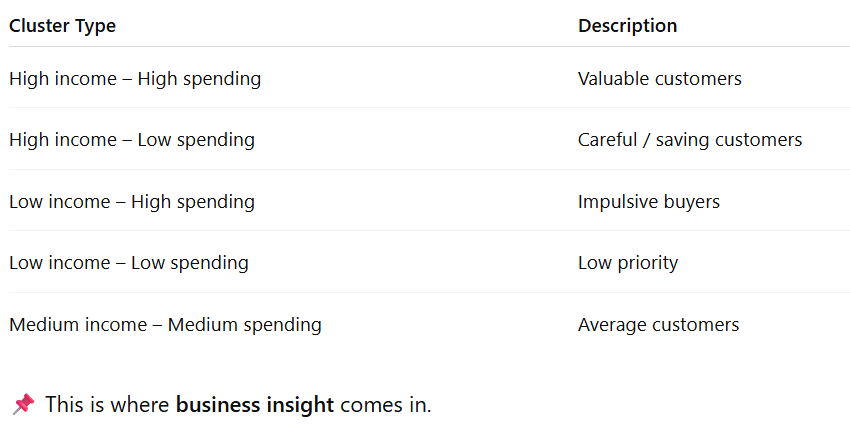